# Sieci Kohonena

In [44]:
import numpy as np
import pandas as pd
import math
from tqdm import tqdm
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import plotly.express as px
import matplotlib.patches as patches
from collections import Counter
from matplotlib.patches import RegularPolygon, Rectangle
from sklearn.datasets import fetch_openml

In [45]:
def funkcja_wygaszajaca(t, wygaszanie):
    return np.exp(- t / wygaszanie)

def funkcja_Gaussa(d2_grid, sigma):
    return np.exp(-d2_grid / (2 * sigma**2))

def meksykanski_kapelusz(d2_grid, sigma):
    val = -d2_grid / (sigma**2)
    return (1 + val) * np.exp(val / 2)

def ij_to_xy(i, j):
    x = j + 0.5 * (i % 2)
    y = i * (np.sqrt(3) / 2)
    return x, y

In [46]:
class Kohonen:
    def __init__(self, M, N, len_wejscia, iteracje, sigma, funkcja_sasiedztwa, wygaszanie, topologia):
        self.M = M
        self.N = N
        self.len_wejscia = len_wejscia
        self.iteracje = iteracje
        self.sigma = sigma
        self.wagi = None
        self.funkcja_sasiedztwa = funkcja_sasiedztwa
        self.wygaszanie = wygaszanie
        self.min_vals = 0
        self.max_vals = 1
        self.topologia = topologia

    def znajdz_najblizszy(self, x):
        # odległość euklidesowa
        odleglosci = np.linalg.norm(self.wagi - x, axis=-1)
        min_idx = np.argmin(odleglosci)
        return np.unravel_index(min_idx, (self.M, self.N))
    
    def update(self, x, best_coord, alpha):
        i_grid, j_grid = np.indices((self.M, self.N))

        if self.topologia == 'szesciokat':
            x_grid, y_grid = ij_to_xy(i_grid, j_grid)
            best_x, best_y = ij_to_xy(best_coord[0], best_coord[1])
            d2_grid = (x_grid - best_x)**2 + (y_grid - best_y)**2
            
        else:
            d2_grid = (i_grid - best_coord[0])**2 + (j_grid - best_coord[1])**2

        theta = self.funkcja_sasiedztwa(d2_grid, self.sigma)
        theta = theta[..., np.newaxis]
        self.wagi += theta * alpha * (x - self.wagi)
        self.wagi = np.clip(self.wagi, self.min_vals, self.max_vals)

    def train(self, data):
        liczba_probek = data.shape[0]

        self.min_vals = np.min(data, axis=0) 
        self.max_vals = np.max(data, axis=0)
        self.wagi = np.random.uniform(self.min_vals, self.max_vals, (self.M, self.N, self.len_wejscia))

        for t in tqdm(range(self.iteracje)):
            alpha = funkcja_wygaszajaca(t, self.wygaszanie)

            indeksy = np.arange(liczba_probek)
            np.random.shuffle(indeksy)
          
            for idx in indeksy:
                x = data[idx] 
                best_coord = self.znajdz_najblizszy(x)
                self.update(x, best_coord, alpha)

In [47]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

In [48]:
def mapping_plot(model, dane, etykiety):
    fig, ax = plt.subplots(figsize=(10, 10))
    
    neurony_klasy = {(i, j): [] for i in range(model.M) for j in range(model.N)}
    etykiety_plaskie = etykiety.flatten()
    
    for idx, x in enumerate(dane):
        bmu_coord = model.znajdz_najblizszy(x)
        neurony_klasy[bmu_coord].append(etykiety_plaskie[idx])
        
    cmap = plt.get_cmap('tab10')
    poprawne_trafienia = 0
    wszystkie_probki = len(dane)
    
    for i in range(model.M):
        for j in range(model.N):
            klasy_w_neuronie = neurony_klasy[(i, j)]
            liczba_punktow = len(klasy_w_neuronie)
            
            if liczba_punktow > 0:
                licznik = Counter(klasy_w_neuronie)
                dominujaca_klasa, liczba_w_dominujacej = licznik.most_common(1)[0]
                poprawne_trafienia += liczba_w_dominujacej
                kolor_tla = cmap(dominujaca_klasa)
                alpha_tla = 0.3
            else:
                kolor_tla = 'white'
                alpha_tla = 1.0
                
            if hasattr(model, 'topologia') and model.topologia == 'szesciokat':
                x_center, y_center = ij_to_xy(i, j)
                promien = 1 / math.sqrt(3) 
                ksztalt = RegularPolygon(
                    (x_center, y_center), numVertices=6, radius=promien, 
                    orientation=math.pi/6,
                    linewidth=1, edgecolor='black', facecolor=kolor_tla, alpha=alpha_tla
                )
            else:
                x_center, y_center = i, j
                ksztalt = Rectangle(
                    (i - 0.5, j - 0.5), 1, 1, 
                    linewidth=1, edgecolor='black', facecolor=kolor_tla, alpha=alpha_tla
                )
                
            ax.add_patch(ksztalt)
            
            if liczba_punktow > 0:
                jitter_x = np.random.uniform(-0.3, 0.3, liczba_punktow)
                jitter_y = np.random.uniform(-0.3, 0.3, liczba_punktow)
                
                px = x_center + jitter_x
                py = y_center + jitter_y
                
                kolory_kropek = [cmap(k) for k in klasy_w_neuronie]
                ax.scatter(px, py, c=kolory_kropek, edgecolors='black', s=30, zorder=5)

    accuracy = poprawne_trafienia / wszystkie_probki
    
    if hasattr(model, 'topologia') and model.topologia == 'szesciokat':
        ax.set_xlim(-1, model.N + 0.5)
        ax.set_ylim(-1, model.M * math.sqrt(3)/2 + 0.5)
    else:
        ax.set_xlim(-0.5, model.M - 0.5)
        ax.set_ylim(-0.5, model.N - 0.5)
        
    ax.set_aspect('equal') 
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'Mapping plot\nAccuracy: {accuracy * 100:.2f}%', fontsize=14, fontweight='bold')
    plt.grid(False) 
    plt.show()
    
    return accuracy

# Dane MNIST

In [49]:
mnist = fetch_openml('mnist_784', version=1, parser='auto')

mnist_data = mnist.data.to_numpy() 
y_etykiety = mnist.target.to_numpy().astype(int)

rozmiar_podzbioru = 10000

mnist_data = mnist_data[:rozmiar_podzbioru]
y_etykiety = y_etykiety[:rozmiar_podzbioru]

mnist_data = mnist_data / 255.0 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = mnist_data.shape[1]

In [50]:
model = Kohonen(10, 10, n, 6, 0.5, funkcja_Gaussa, 3, 'szesciokat')
model.train(mnist_data)

100%|██████████| 6/6 [00:44<00:00,  7.47s/it]


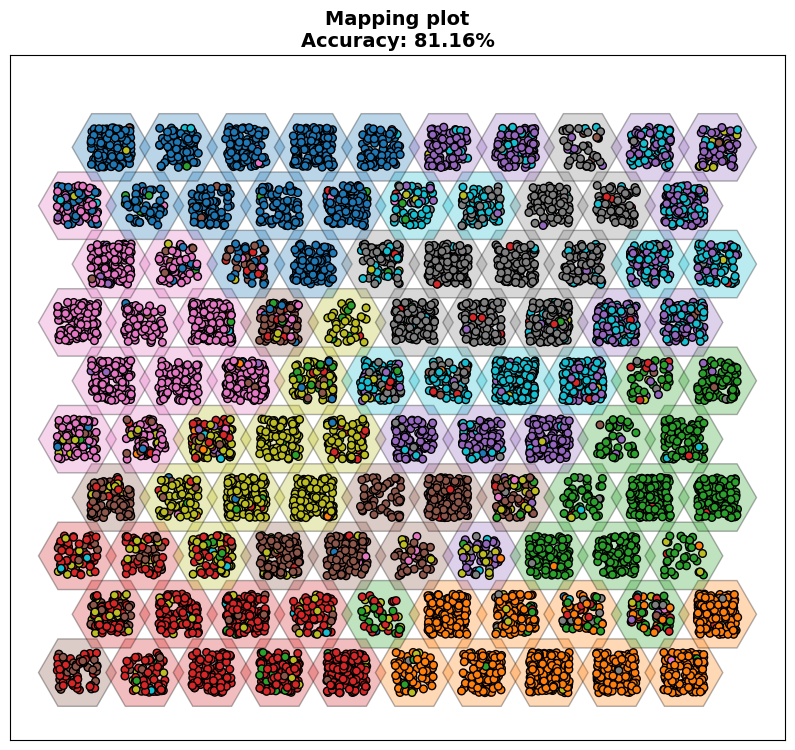

In [51]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

In [52]:
model = Kohonen(15, 15, n, 6, 0.5, funkcja_Gaussa, 3, 'szesciokat')
model.train(mnist_data)

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [02:56<00:00, 29.40s/it]


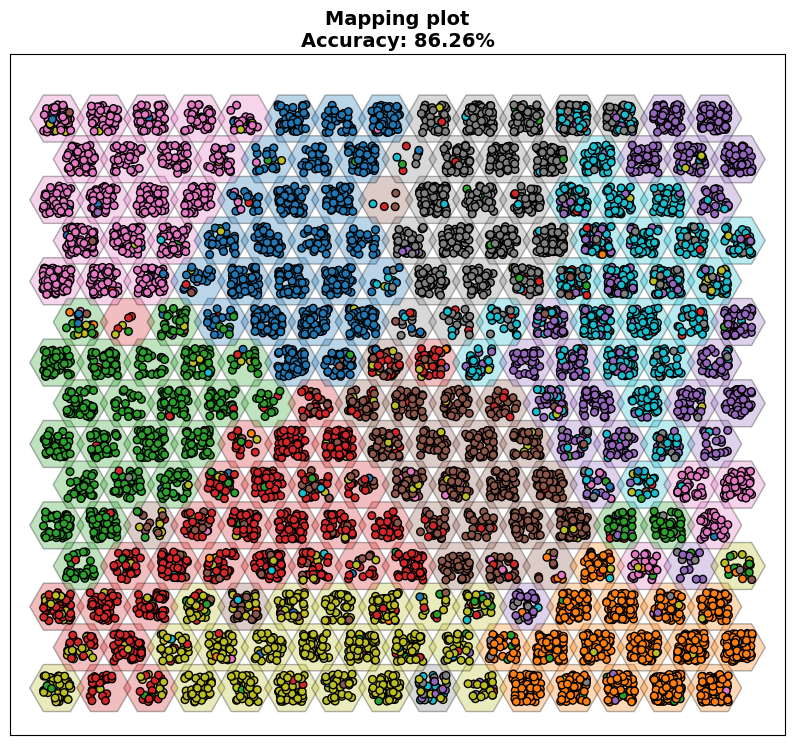

In [53]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

In [54]:
model = Kohonen(15, 15, n, 6, 0.5, funkcja_Gaussa, 3, 'szesciokat')
model.train(mnist_data)

100%|██████████| 6/6 [02:26<00:00, 24.50s/it]


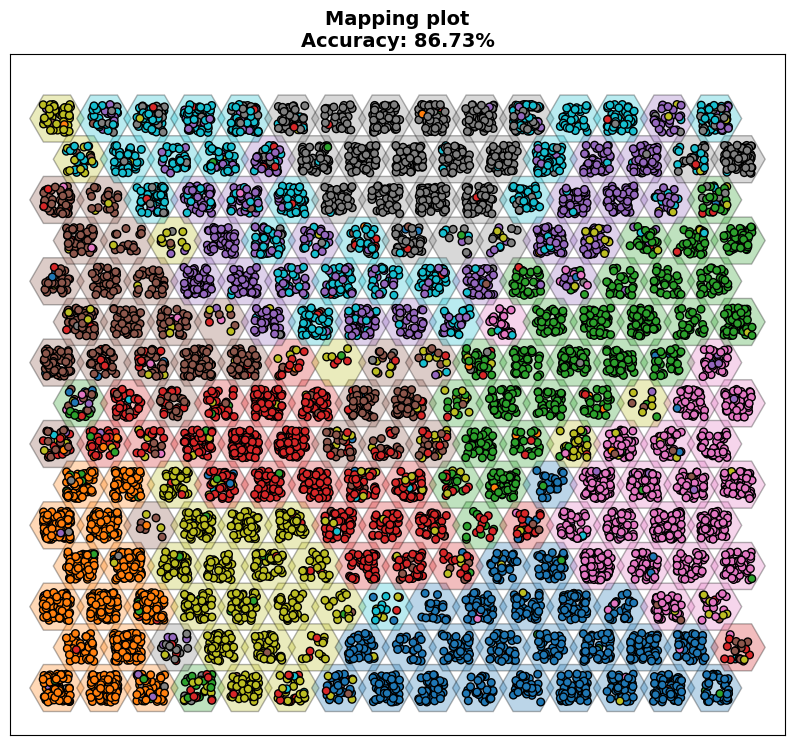

In [55]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

In [56]:
model = Kohonen(20, 20, n, 6, 0.5, funkcja_Gaussa, 3, 'szesciokat')
model.train(mnist_data)

100%|██████████| 6/6 [04:50<00:00, 48.50s/it]


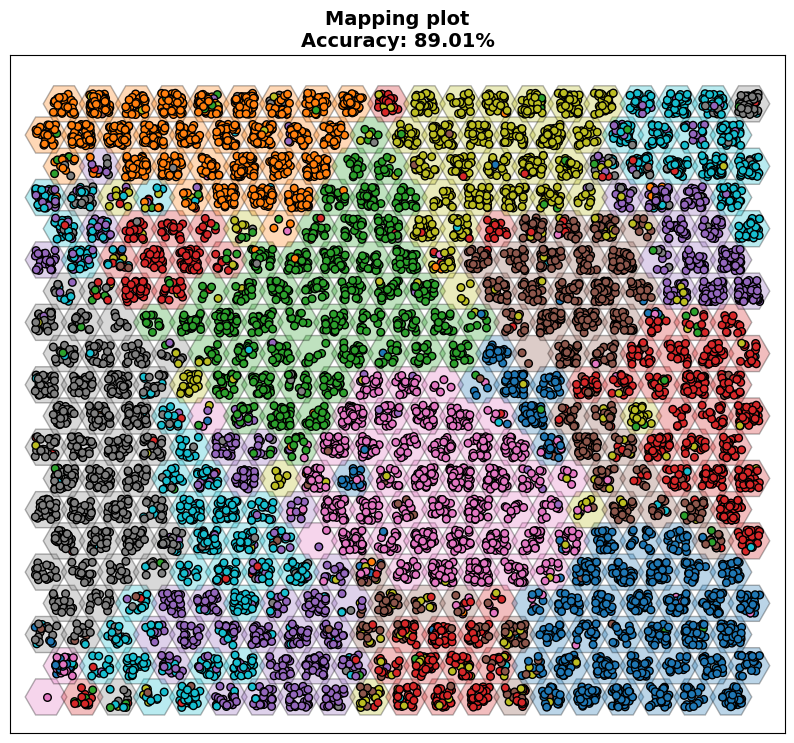

In [57]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

In [58]:
model = Kohonen(10, 10, n, 6, 6, meksykanski_kapelusz, 3, 'szesciokat')
model.train(mnist_data)

100%|██████████| 6/6 [00:26<00:00,  4.42s/it]


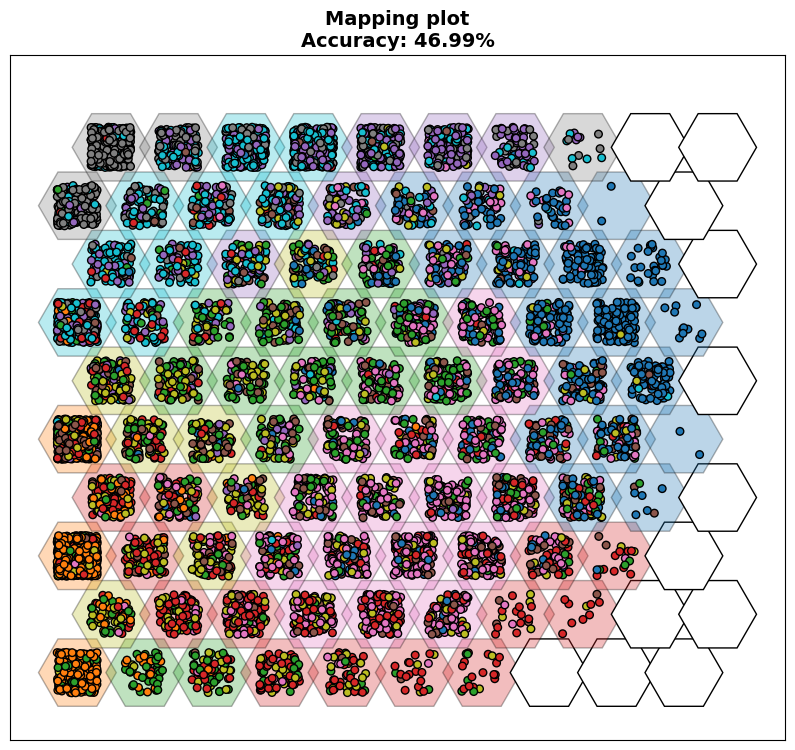

In [59]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

In [60]:
model = Kohonen(15, 15, n, 6, 8, meksykanski_kapelusz, 3, 'szesciokat')
model.train(mnist_data)

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [02:29<00:00, 24.92s/it]


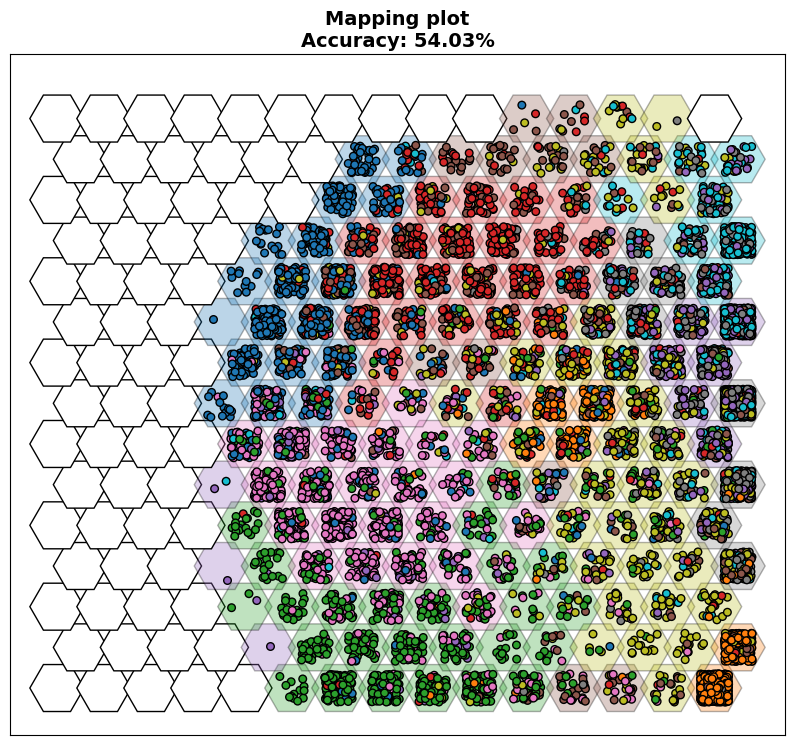

In [61]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

## Najlepszy model

In [80]:
mnist = fetch_openml('mnist_784', version=1, parser='auto')

mnist_data = mnist.data.to_numpy() 
y_etykiety = mnist.target.to_numpy().astype(int)

mnist_data = mnist_data / 255.0 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = mnist_data.shape[1]

In [63]:
model = Kohonen(16, 16, n, 6, 0.5, funkcja_Gaussa, 3, 'szesciokat')
model.train(mnist_data)

100%|██████████| 6/6 [19:51<00:00, 198.61s/it]


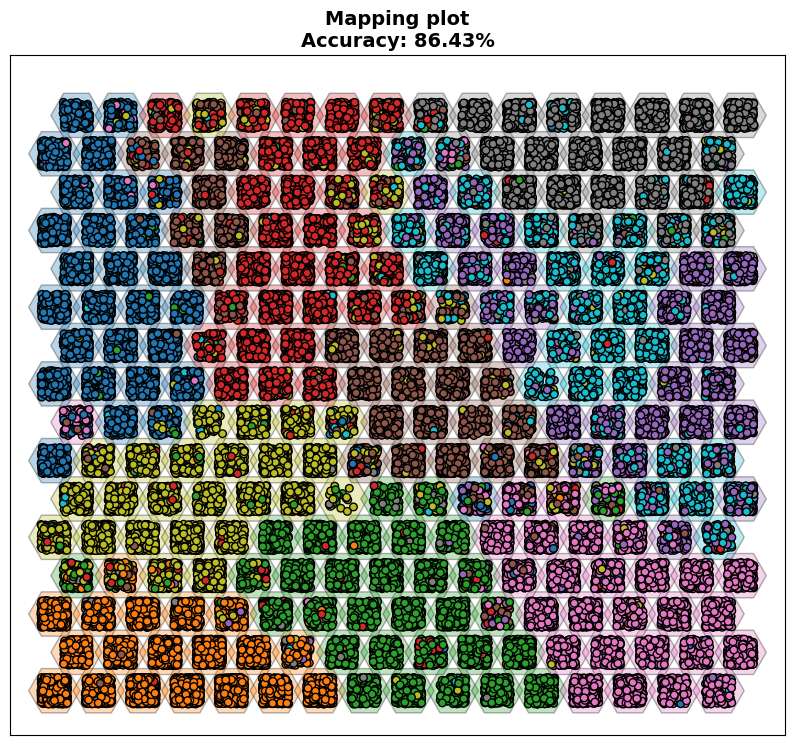

In [64]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

In [81]:
model = Kohonen(16, 16, n, 6, 0.5, funkcja_Gaussa, 3, 'kwadrat')
model.train(mnist_data)

100%|██████████| 6/6 [20:12<00:00, 202.07s/it]


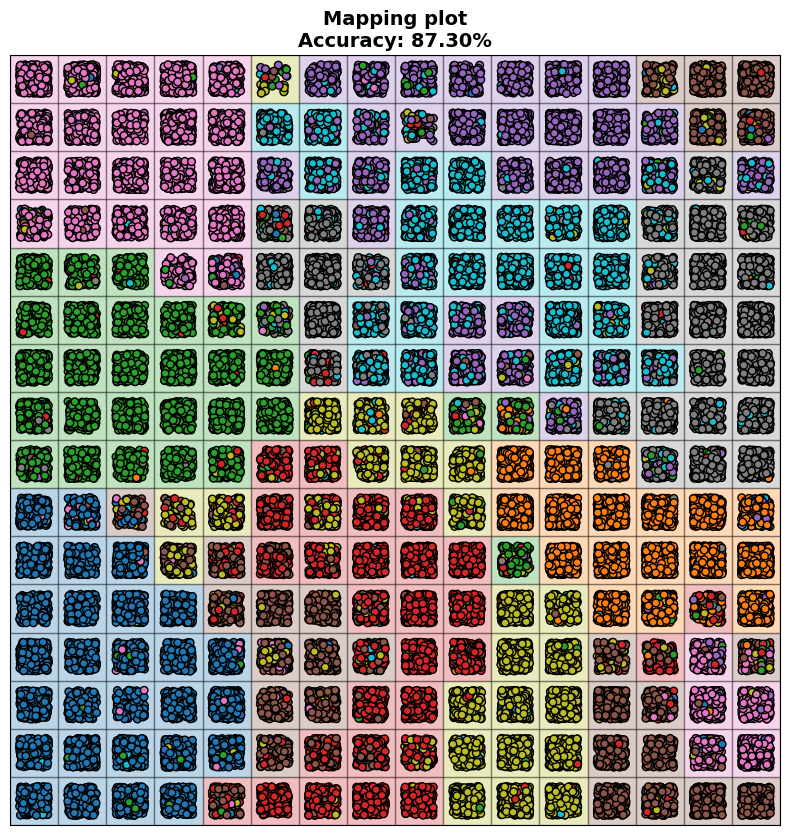

In [82]:
accuracy = mapping_plot(model, mnist_data, y_etykiety)

# Dane HAR

In [83]:
har_data = pd.read_csv("mio2/HAR/UCI HAR Dataset/UCI HAR Dataset/train/X_train.txt", sep=r'\s+', header=None)
y_etykiety = pd.read_csv("mio2/HAR/UCI HAR Dataset/UCI HAR Dataset/train/y_train.txt", sep=r'\s+', header=None)

har_data = har_data.to_numpy() 
y_etykiety = y_etykiety.to_numpy().astype(int) - 1 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = har_data.shape[1]

In [66]:
model = Kohonen(15, 15, n, 10, 0.5, funkcja_Gaussa, 5, 'szesciokat')
model.train(har_data)

100%|██████████| 10/10 [00:52<00:00,  5.29s/it]


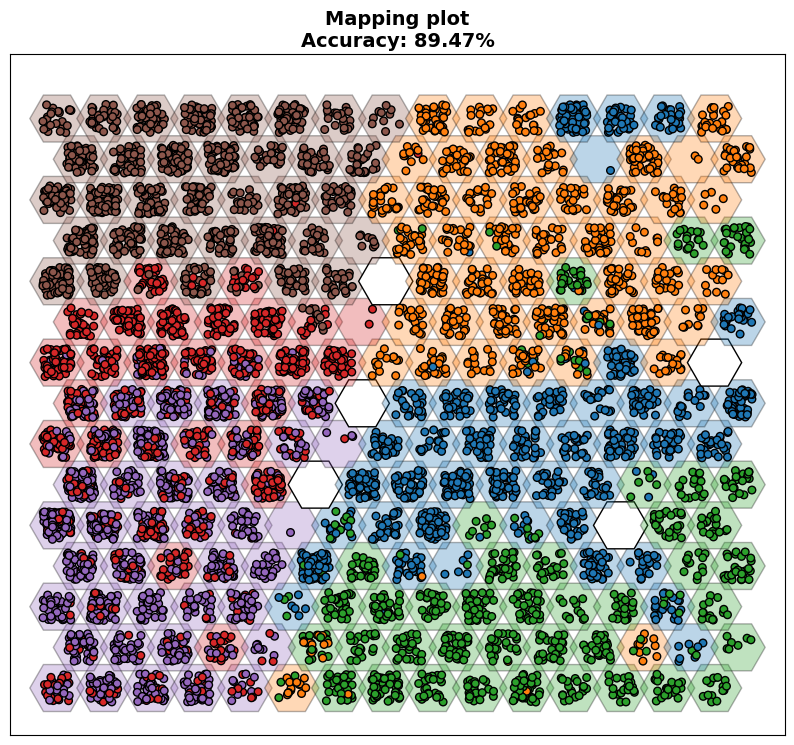

In [67]:
accuracy = mapping_plot(model, har_data, y_etykiety)

In [68]:
model = Kohonen(15, 15, n, 10, 1, funkcja_Gaussa, 5, 'szesciokat')
model.train(har_data)

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:50<00:00,  5.07s/it]


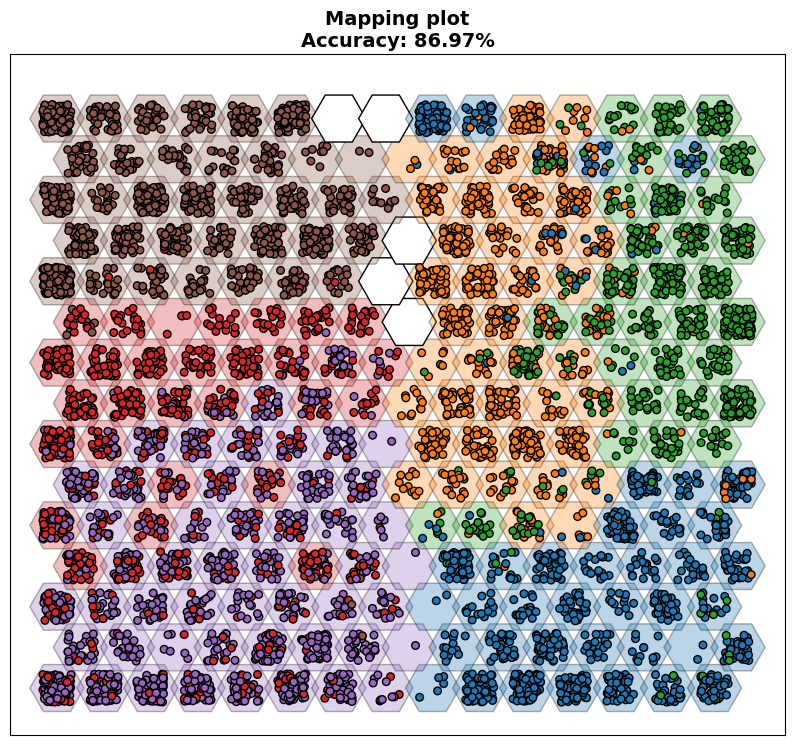

In [69]:
accuracy = mapping_plot(model, har_data, y_etykiety)

In [70]:
model = Kohonen(15, 15, n, 10, 0.5, funkcja_Gaussa, 5, 'kwadrat')
model.train(har_data)

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:50<00:00,  5.00s/it]


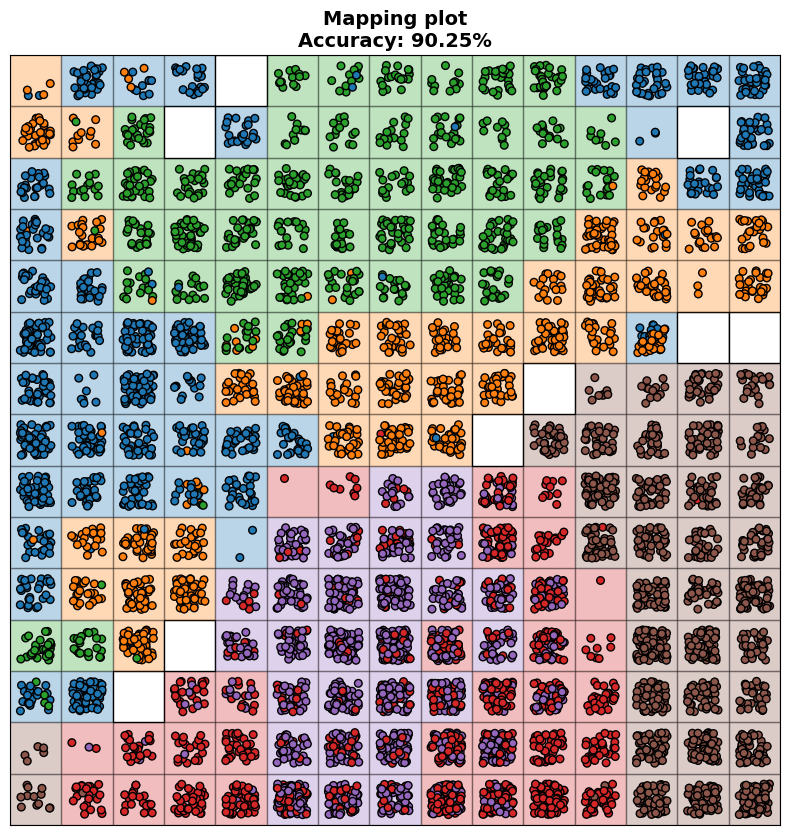

In [71]:
accuracy = mapping_plot(model, har_data, y_etykiety)

In [72]:
model = Kohonen(15, 15, n, 10, 0.5, meksykanski_kapelusz, 5, 'szesciokat')
model.train(har_data)

100%|██████████| 10/10 [00:51<00:00,  5.18s/it]


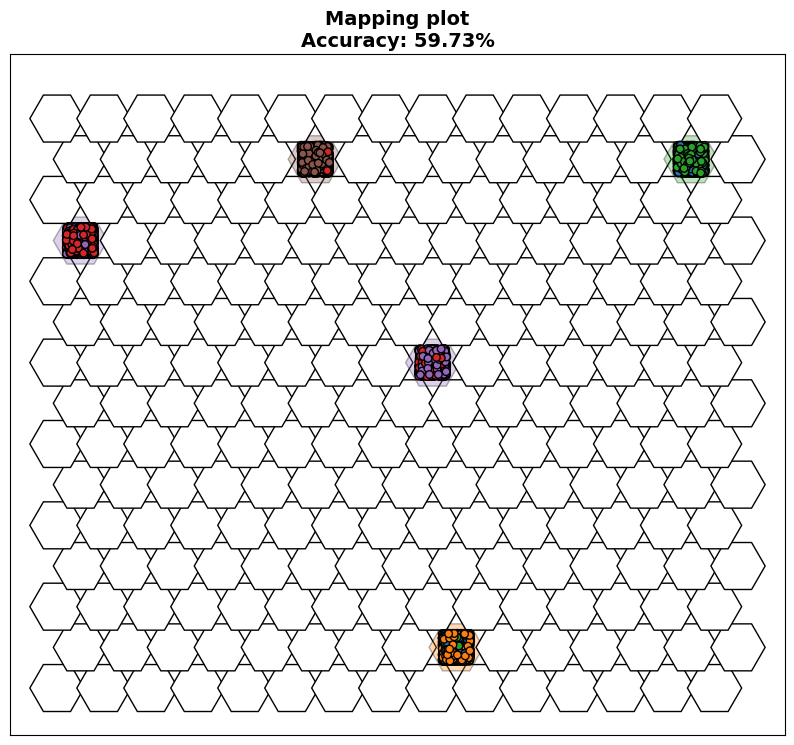

In [73]:
accuracy = mapping_plot(model, har_data, y_etykiety)

In [74]:
model = Kohonen(15, 15, n, 10, 5, meksykanski_kapelusz, 5, 'szesciokat')
model.train(har_data)

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:50<00:00,  5.09s/it]


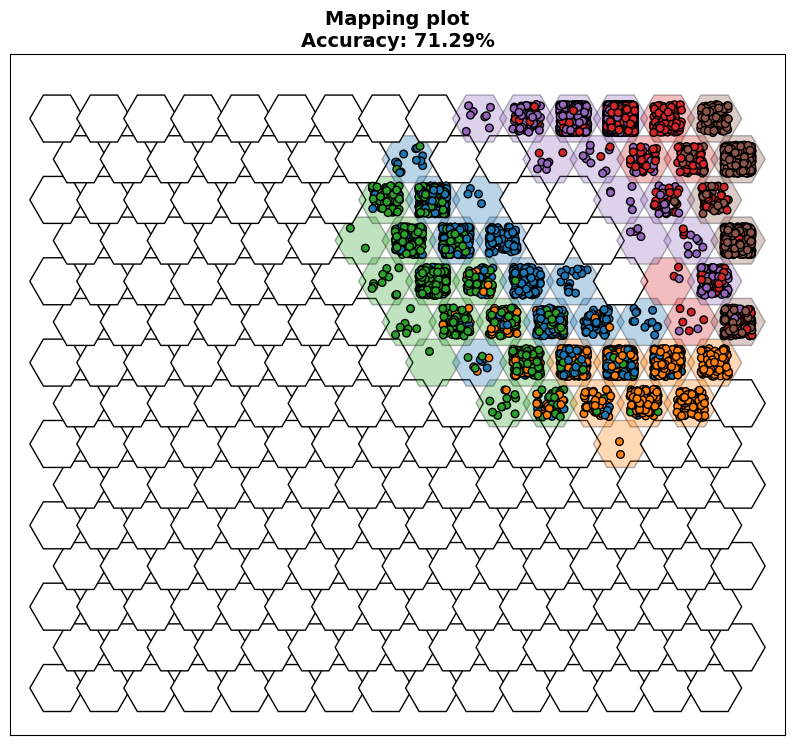

In [75]:
accuracy = mapping_plot(model, har_data, y_etykiety)

In [76]:
model = Kohonen(10, 10, n, 10, 8, meksykanski_kapelusz, 5, 'szesciokat')
model.train(har_data)

100%|██████████| 10/10 [00:22<00:00,  2.22s/it]


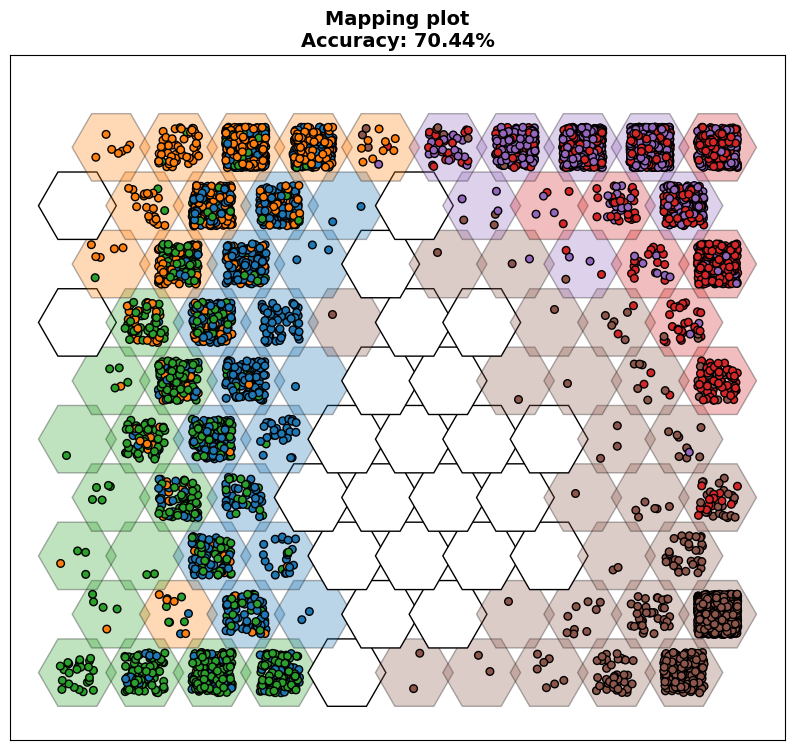

In [77]:
accuracy = mapping_plot(model, har_data, y_etykiety)

## Najlepszy model

In [78]:
model = Kohonen(15, 15, n, 10, 0.5, funkcja_Gaussa, 5, 'szesciokat')
model.train(har_data)

100%|██████████| 10/10 [00:53<00:00,  5.39s/it]


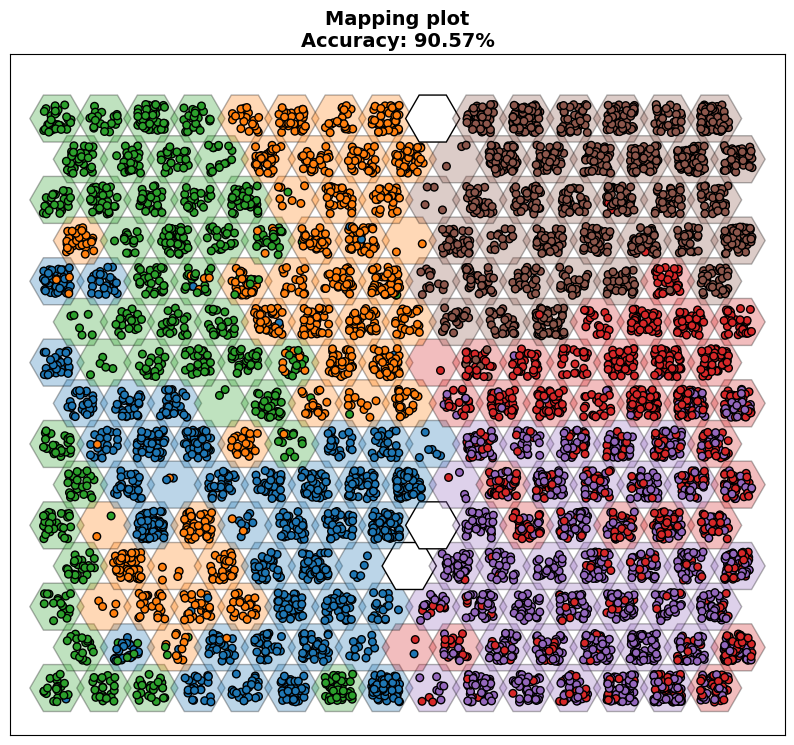

In [79]:
accuracy = mapping_plot(model, har_data, y_etykiety)

In [84]:
model = Kohonen(15, 15, n, 10, 0.5, funkcja_Gaussa, 5, 'kwadrat')
model.train(har_data)

100%|██████████| 10/10 [00:50<00:00,  5.01s/it]


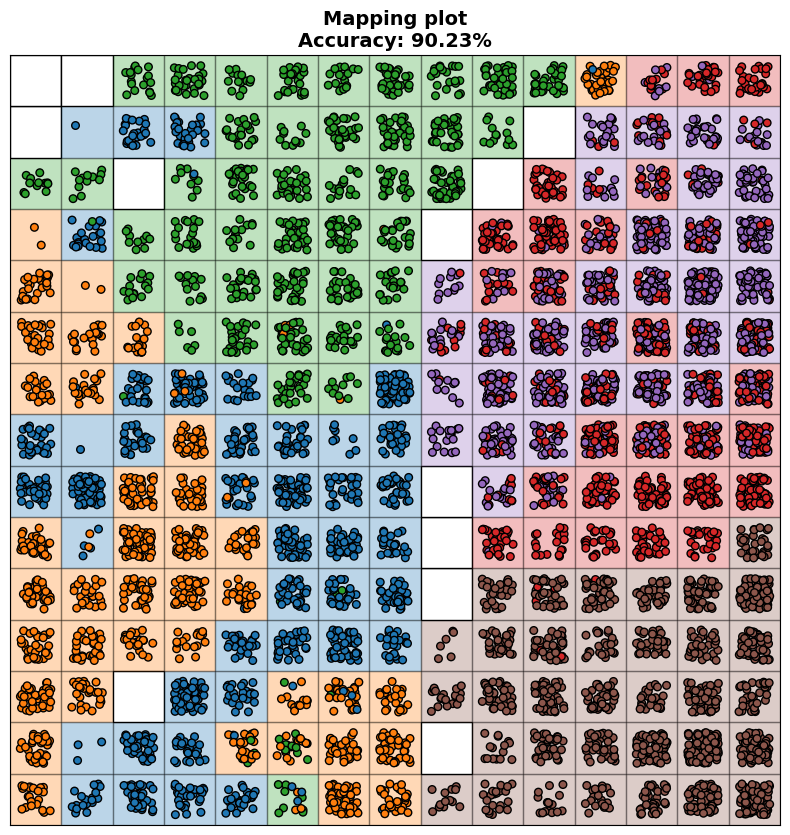

In [85]:
accuracy = mapping_plot(model, har_data, y_etykiety)